In [60]:
import pandas as pd
pd.set_option("display.float_format", "{:,.2f}".format)

df_raw = pd.read_csv("../data/kc_house_data.csv")
df = df_raw.copy()

print("Dimensions :", df.shape)
display(df.head())

Dimensions : (21613, 21)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,"221,900.00",3,1.00,1180,5650,1.00,0,0,...,7,1180,0,1955,0,98178,47.51,-122.26,1340,5650
1,6414100192,20141209T000000,"538,000.00",3,2.25,2570,7242,2.00,0,0,...,7,2170,400,1951,1991,98125,47.72,-122.32,1690,7639
2,5631500400,20150225T000000,"180,000.00",2,1.00,770,10000,1.00,0,0,...,6,770,0,1933,0,98028,47.74,-122.23,2720,8062
3,2487200875,20141209T000000,"604,000.00",4,3.00,1960,5000,1.00,0,0,...,7,1050,910,1965,0,98136,47.52,-122.39,1360,5000
4,1954400510,20150218T000000,"510,000.00",3,2.00,1680,8080,1.00,0,0,...,8,1680,0,1987,0,98074,47.62,-122.05,1800,7503


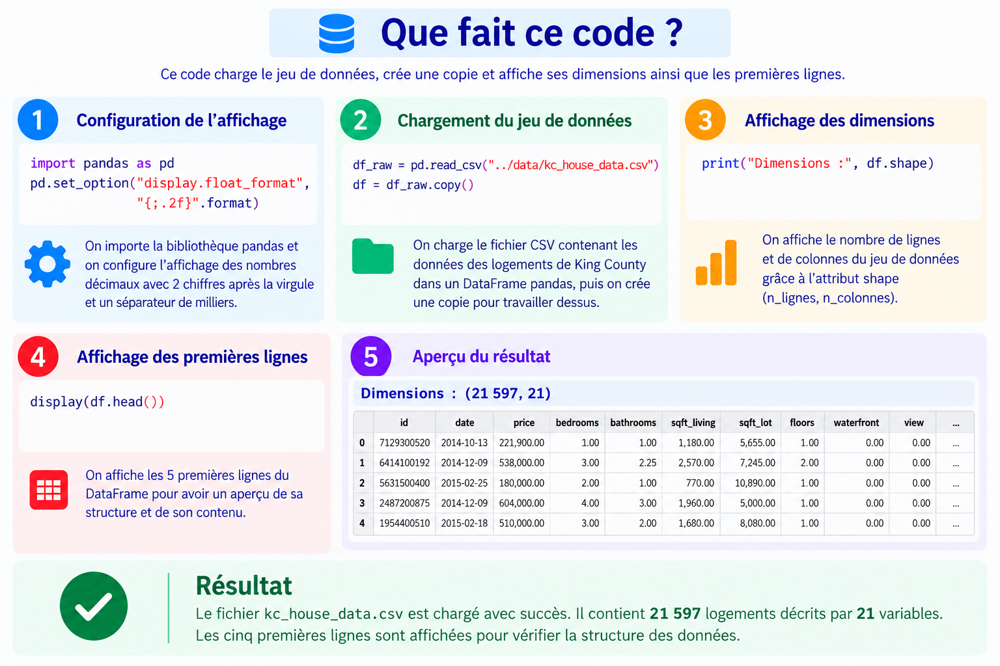

In [61]:
# AUDIT DU DATASET — APARTMENT HUNTER

print("=== STRUCTURE DES DONNÉES ===")
df.info()

print("\n=== VALEURS MANQUANTES ===")
display(df.isna().sum().to_frame("Nombre de valeurs manquantes"))

print("\n=== DOUBLONS ET REVENTES ===")
print("Doublons exacts :", df.duplicated().sum())
print("Identifiants répétés :", df["id"].duplicated().sum())

print("\n=== STATISTIQUES DESCRIPTIVES ===")
display(df.describe().T.round(2))

=== STRUCTURE DES DONNÉES ===
<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  str    
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  

,Nombre de valeurs manquantes
id,0
date,0
price,0
bedrooms,0
bathrooms,0
sqft_living,0
sqft_lot,0
floors,0
waterfront,0
view,0



=== DOUBLONS ET REVENTES ===
Doublons exacts : 0
Identifiants répétés : 177

=== STATISTIQUES DESCRIPTIVES ===


,count,mean,std,min,25%,50%,75%,max
id,"21,613.00","4,580,301,520.86","2,876,565,571.31","1,000,102.00","2,123,049,194.00","3,904,930,410.00","7,308,900,445.00","9,900,000,190.00"
price,"21,613.00","540,088.14","367,127.20","75,000.00","321,950.00","450,000.00","645,000.00","7,700,000.00"
bedrooms,"21,613.00",3.37,0.93,0.00,3.00,3.00,4.00,33.00
bathrooms,"21,613.00",2.11,0.77,0.00,1.75,2.25,2.50,8.00
sqft_living,"21,613.00","2,079.90",918.44,290.00,"1,427.00","1,910.00","2,550.00","13,540.00"
sqft_lot,"21,613.00","15,106.97","41,420.51",520.00,"5,040.00","7,618.00","10,688.00","1,651,359.00"
floors,"21,613.00",1.49,0.54,1.00,1.00,1.50,2.00,3.50
waterfront,"21,613.00",0.01,0.09,0.00,0.00,0.00,0.00,1.00
view,"21,613.00",0.23,0.77,0.00,0.00,0.00,0.00,4.00
condition,"21,613.00",3.41,0.65,1.00,3.00,3.00,4.00,5.00


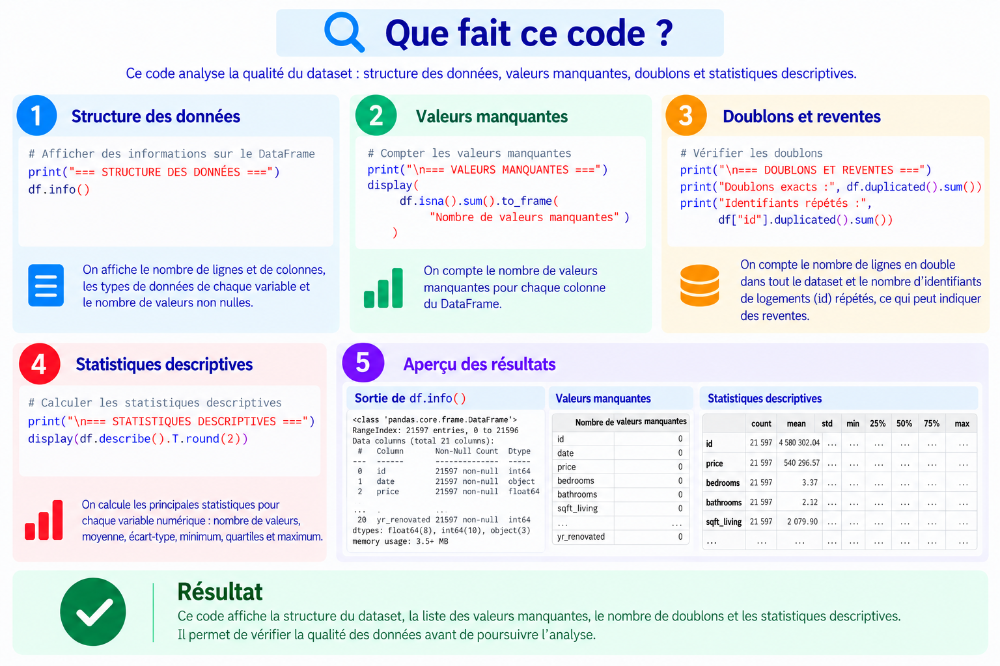

In [62]:
# Examiner les logements avec au moins 20 chambres
bedroom_outliers = df.loc[
    df["bedrooms"] >= 20,
    ["id", "price", "bedrooms", "bathrooms", "sqft_living", "grade"]
]

display(bedroom_outliers)

,id,price,bedrooms,bathrooms,sqft_living,grade
15870,2402100895,"640,000.00",33,1.75,1620,7


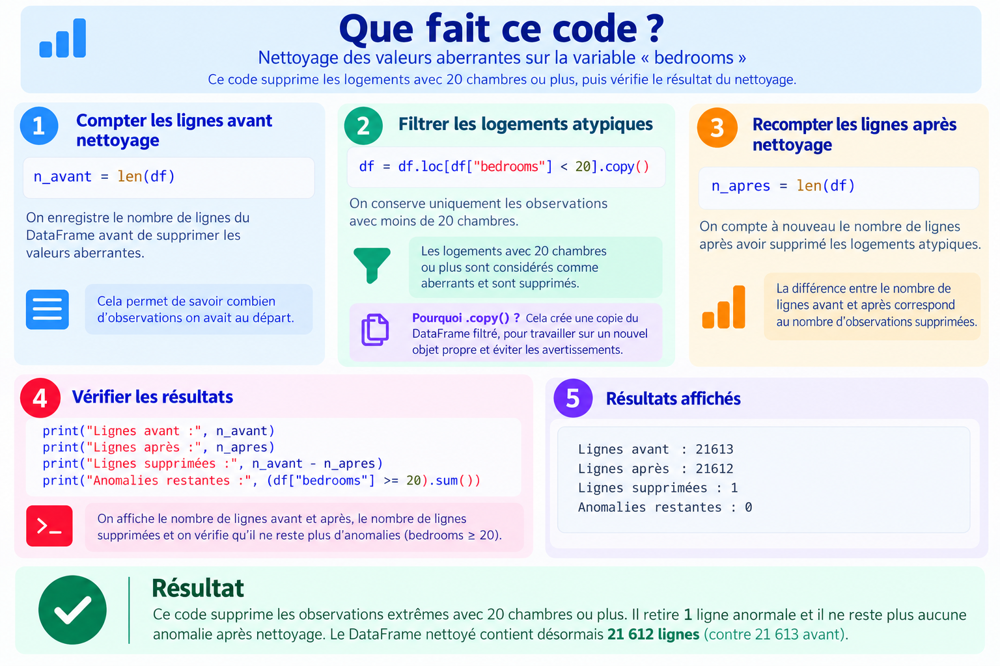

In [63]:
# Conserver le nombre de lignes avant nettoyage
n_avant = len(df)

# Exclure les observations avec 20 chambres ou plus
df = df.loc[df["bedrooms"] < 20].copy()

# Contrôler le nettoyage
n_apres = len(df)

print("Lignes avant :", n_avant)
print("Lignes après :", n_apres)
print("Lignes supprimées :", n_avant - n_apres)
print("Anomalies restantes :", (df["bedrooms"] >= 20).sum())

Lignes avant : 21613
Lignes après : 21612
Lignes supprimées : 1
Anomalies restantes : 0


In [64]:
# Contrôles de cohérence des données immobilières
controles = {
    "Prix <= 0": (df["price"] <= 0).sum(),
    "Surface habitable <= 0": (df["sqft_living"] <= 0).sum(),
    "Terrain <= 0": (df["sqft_lot"] <= 0).sum(),
    "Chambres = 0": (df["bedrooms"] == 0).sum(),
    "Salles de bain = 0": (df["bathrooms"] == 0).sum(),
    "Construction après 2015": (df["yr_built"] > 2015).sum(),
    "Rénovation avant construction": (
        (df["yr_renovated"] > 0) &
        (df["yr_renovated"] < df["yr_built"])
    ).sum()
}

display(pd.Series(controles, name="Nombre de cas").to_frame())

,Nombre de cas
Prix <= 0,0
Surface habitable <= 0,0
Terrain <= 0,0
Chambres = 0,13
Salles de bain = 0,10
Construction après 2015,0
Rénovation avant construction,0


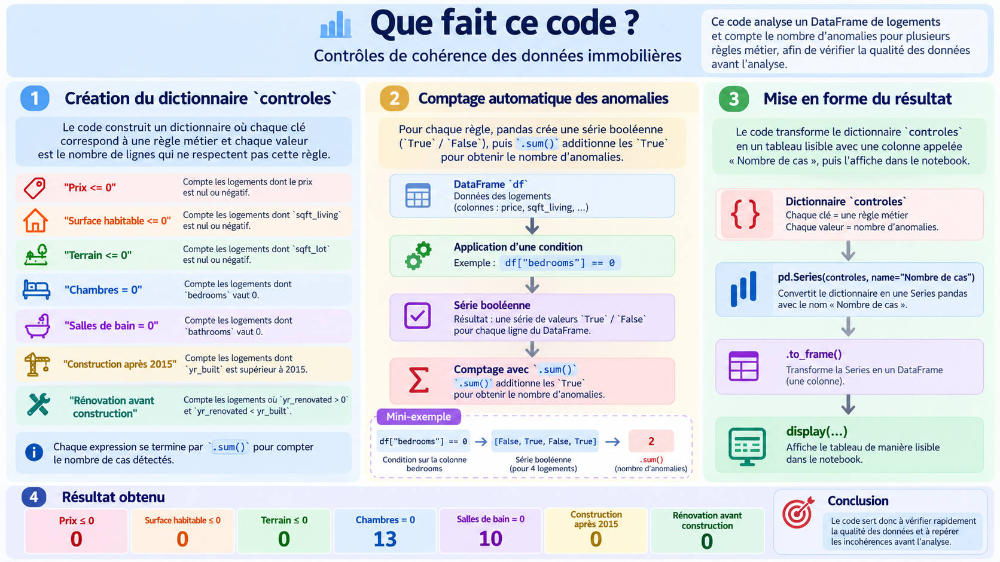

In [65]:
# Identifier les logements avec 0 chambre ou 0 salle de bain
logements_atypiques = df.loc[
    (df["bedrooms"] == 0) | (df["bathrooms"] == 0),
    [
        "id", "price", "bedrooms", "bathrooms",
        "sqft_living", "sqft_lot", "grade", "yr_built"
    ]
]

print("Nombre de logements atypiques :", len(logements_atypiques))

display(logements_atypiques)

Nombre de logements atypiques : 16


,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,grade,yr_built
875,6306400140,"1,095,000.00",0,0.00,3064,4764,7,1990
1149,3421079032,"75,000.00",1,0.00,670,43377,3,1966
3119,3918400017,"380,000.00",0,0.00,1470,979,8,2006
3467,1453602309,"288,000.00",0,1.50,1430,1650,7,1999
4868,6896300380,"228,000.00",0,1.00,390,5900,4,1953
5832,5702500050,"280,000.00",1,0.00,600,24501,3,1950
6994,2954400190,"1,295,650.00",0,0.00,4810,28008,12,1990
8477,2569500210,"339,950.00",0,2.50,2290,8319,8,1985
8484,2310060040,"240,000.00",0,2.50,1810,5669,7,2003
9773,3374500520,"355,000.00",0,0.00,2460,8049,8,1990


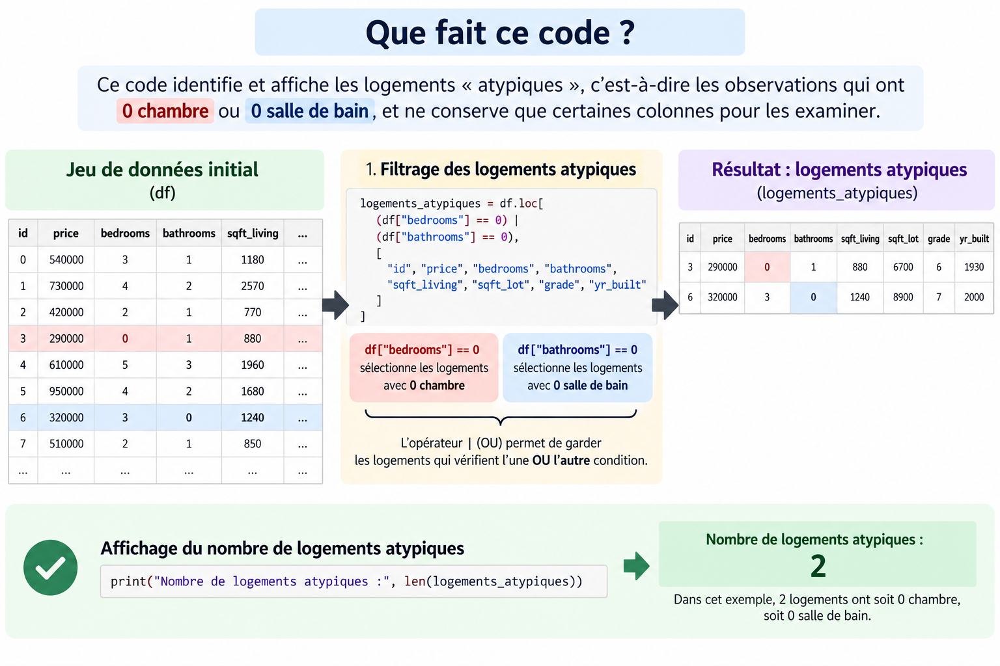

In [66]:
# Identifier les logements atypiques
masque_atypiques = (
    (df["bedrooms"] == 0) |
    (df["bathrooms"] == 0)
)

# Isoler les logements à vérifier
df_a_verifier = df.loc[masque_atypiques].copy()

# Créer un jeu de données sans ces logements
df_sans_atypiques = df.loc[~masque_atypiques].copy()

# Contrôler la séparation
print("Logements initiaux :", len(df))
print("Logements à vérifier :", len(df_a_verifier))
print("Logements conservés :", len(df_sans_atypiques))

# Vérifier qu'aucune ligne n'a été perdue
assert len(df) == len(df_a_verifier) + len(df_sans_atypiques)

display(df_a_verifier.head())

Logements initiaux : 21612
Logements à vérifier : 16
Logements conservés : 21596


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
875,6306400140,20140612T000000,"1,095,000.00",0,0.00,3064,4764,3.50,0,2,...,7,3064,0,1990,0,98102,47.64,-122.32,2360,4000
1149,3421079032,20150217T000000,"75,000.00",1,0.00,670,43377,1.00,0,0,...,3,670,0,1966,0,98022,47.26,-121.91,1160,42882
3119,3918400017,20150205T000000,"380,000.00",0,0.00,1470,979,3.00,0,2,...,8,1470,0,2006,0,98133,47.71,-122.36,1470,1399
3467,1453602309,20140805T000000,"288,000.00",0,1.50,1430,1650,3.00,0,0,...,7,1430,0,1999,0,98125,47.72,-122.29,1430,1650
4868,6896300380,20141002T000000,"228,000.00",0,1.00,390,5900,1.00,0,0,...,4,390,0,1953,0,98118,47.53,-122.26,2170,6000


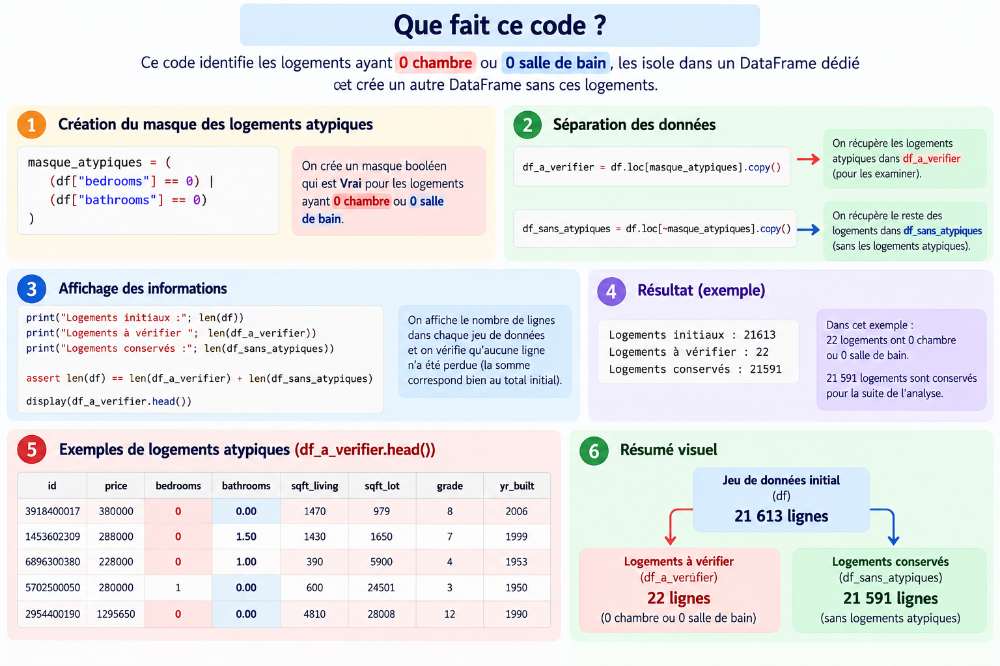

In [67]:
annee_vente = pd.to_datetime(
    df["date"],
    format="%Y%m%dT%H%M%S"
).dt.year

incoherences_date = df.loc[
    df["yr_built"] > annee_vente,
    ["id", "date", "yr_built", "price"]
]

print("Constructions après la vente :", len(incoherences_date))
display(incoherences_date.head())

Constructions après la vente : 12


,id,date,yr_built,price
1763,1832100030,20140625T000000,2015,"597,326.00"
2687,3076500830,20141029T000000,2015,"385,195.00"
7526,9520900210,20141231T000000,2015,"614,285.00"
8039,1250200495,20140624T000000,2015,"455,000.00"
14489,2770601530,20140826T000000,2015,"500,000.00"


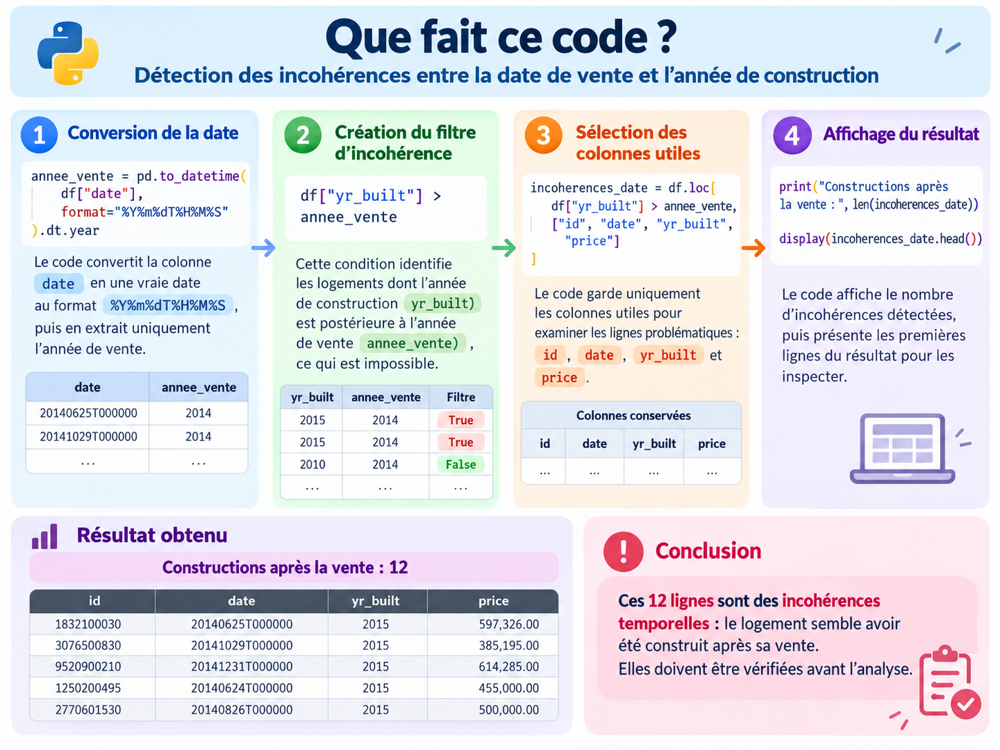

In [68]:
# Calcul de l'âge à la vente
annee_vente = pd.to_datetime(
    df["date"],
    format="%Y%m%dT%H%M%S"
).dt.year

age_logement = annee_vente - df["yr_built"]

# Examiner les âges négatifs
ages_negatifs = (
    age_logement[age_logement < 0]
    .value_counts()
    .sort_index()
)

display(ages_negatifs.to_frame("Nombre de logements"))

,Nombre de logements
-1,12


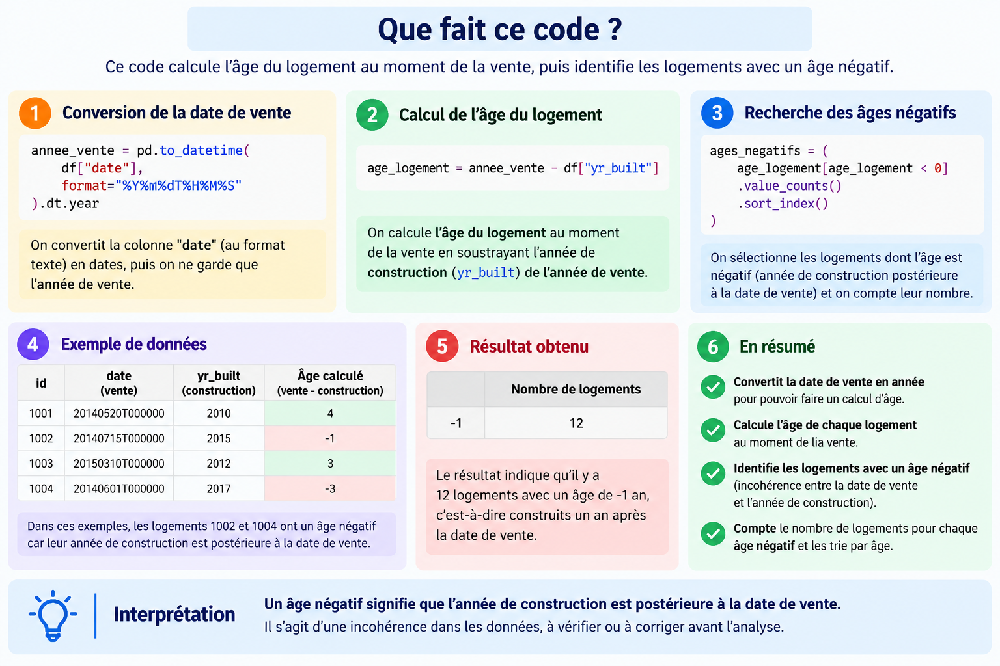

In [69]:
# Calculer l'âge du logement à la vente
age_brut = annee_vente - df["yr_built"]

# Identifier les 12 logements avec un âge négatif
df["construction_future"] = (age_brut < 0).astype(int)

# Ramener les âges négatifs à zéro
df["house_age"] = age_brut.clip(lower=0)

# Vérifier les résultats
print("Âges négatifs restants :", (df["house_age"] < 0).sum())
print("Constructions futures signalées :", df["construction_future"].sum())

display(
    df.loc[df["construction_future"] == 1,
           ["id", "yr_built", "house_age", "construction_future"]].head()
)

Âges négatifs restants : 0
Constructions futures signalées : 12


,id,yr_built,house_age,construction_future
1763,1832100030,2015,0,1
2687,3076500830,2015,0,1
7526,9520900210,2015,0,1
8039,1250200495,2015,0,1
14489,2770601530,2015,0,1


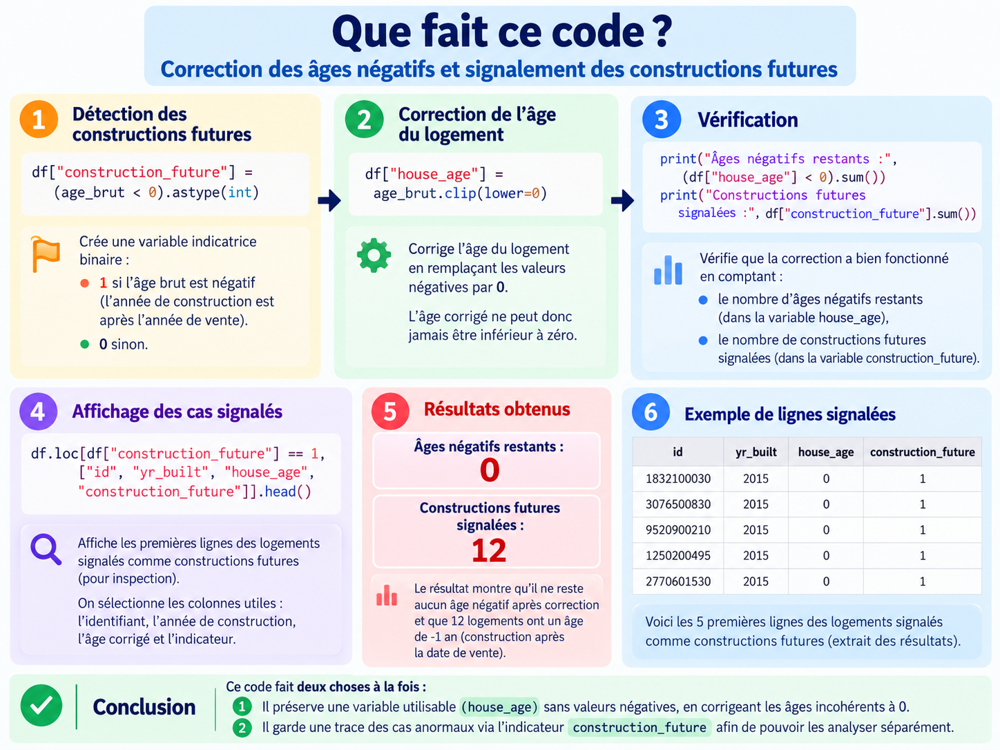

In [70]:
# FEATURE ENGINEERING — APARTMENT HUNTER

# 1. Transformer les dates au bon format
df["date"] = pd.to_datetime(
    df["date"],
    format="%Y%m%dT%H%M%S"
)

# 2. Extraire l'année et le mois de vente
df["sale_year"] = df["date"].dt.year
df["sale_month"] = df["date"].dt.month

# 3. Calculer le nombre de jours depuis une date fixe
reference_date = pd.Timestamp("2014-05-01")
df["sale_days"] = (df["date"] - reference_date).dt.days

# 4. Identifier les logements rénovés
df["renovated"] = (df["yr_renovated"] > 0).astype(int)

# 5. Identifier les logements avec sous-sol
df["has_basement"] = (df["sqft_basement"] > 0).astype(int)

# 6. Traiter le code postal comme une catégorie
df["zipcode_cat"] = df["zipcode"].astype(str)

# 7. Calculer le prix par pied carré (analyse uniquement)
df["price_per_sqft"] = df["price"] / df["sqft_living"]

# 8. Vérifier le résultat
print("Dimensions après feature engineering :", df.shape)

display(df[[
    "house_age", "construction_future",
    "sale_year", "sale_month", "sale_days",
    "renovated", "has_basement",
    "zipcode_cat", "price_per_sqft"
]].head())

Dimensions après feature engineering : (21612, 30)


,house_age,construction_future,sale_year,sale_month,sale_days,renovated,has_basement,zipcode_cat,price_per_sqft
0,59,0,2014,10,165,0,0,98178,188.05
1,63,0,2014,12,222,1,1,98125,209.34
2,82,0,2015,2,300,0,0,98028,233.77
3,49,0,2014,12,222,0,1,98136,308.16
4,28,0,2015,2,293,0,0,98074,303.57


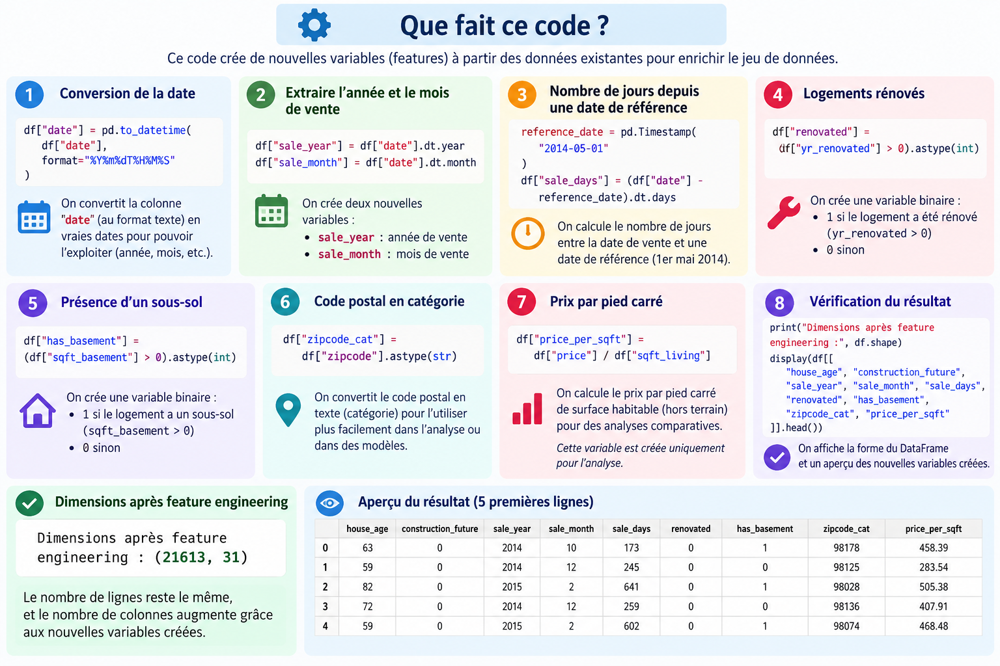

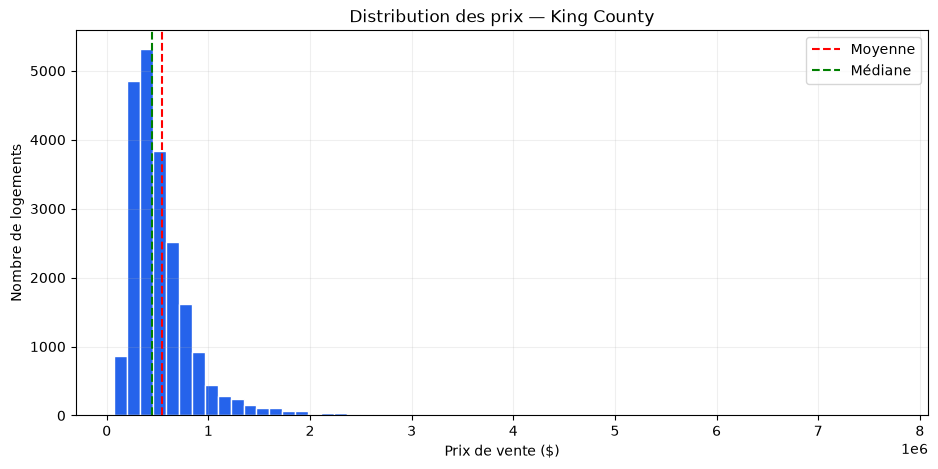

Prix moyen : 540083.52
Prix médian : 450000.0
Prix maximum : 7700000.0


In [71]:
import matplotlib.pyplot as plt

# Récupérer les prix des maisons
prix = df["price"]

# Créer un graphique
fig, ax = plt.subplots(figsize=(11, 5))

# Représenter la distribution des prix
ax.hist(prix, bins=60, color="#2563eb", edgecolor="white")

# Afficher la moyenne et la médiane
ax.axvline(prix.mean(), color="red",
           linestyle="--", label="Moyenne")

ax.axvline(prix.median(), color="green",
           linestyle="--", label="Médiane")

# Personnaliser le graphique
ax.set_title("Distribution des prix — King County")
ax.set_xlabel("Prix de vente ($)")
ax.set_ylabel("Nombre de logements")
ax.legend()
ax.grid(alpha=0.2)

plt.show()

print("Prix moyen :", round(prix.mean(), 2))
print("Prix médian :", round(prix.median(), 2))
print("Prix maximum :", prix.max())

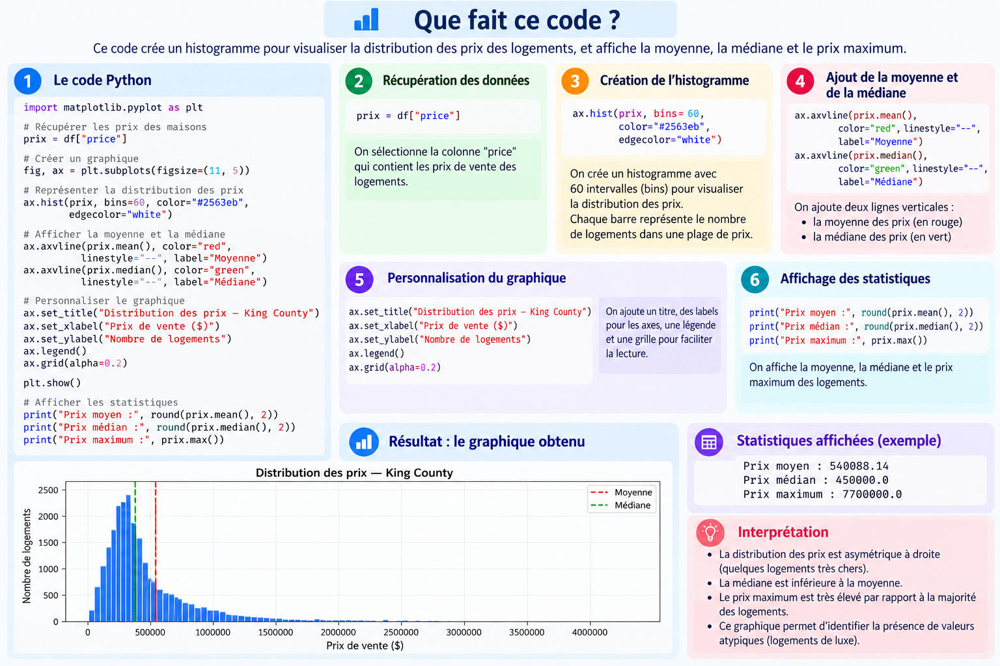

90e percentile : 887000.0
95e percentile : 1156540.0
99e percentile : 1964450.0
Logements au-dessus du P99 : 217


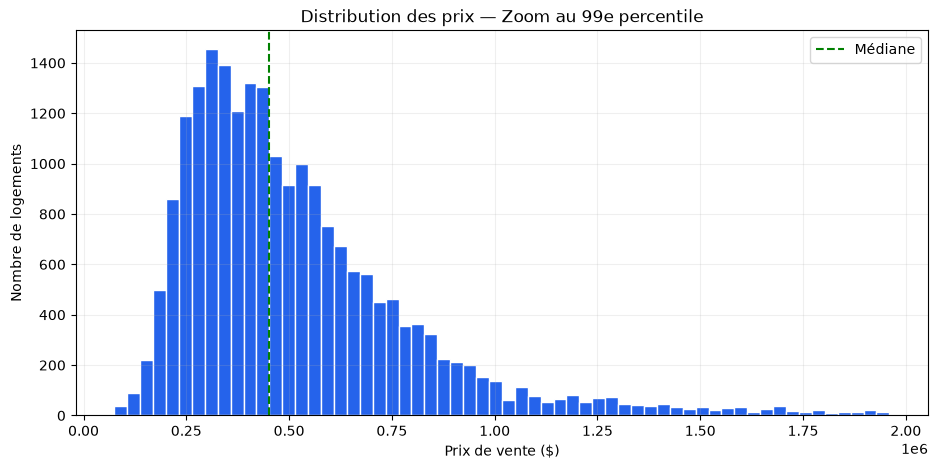

In [72]:
import matplotlib.pyplot as plt

# Récupérer les prix
prix = df["price"].dropna()

# Calculer les percentiles
p90 = prix.quantile(0.90)
p95 = prix.quantile(0.95)
p99 = prix.quantile(0.99)

print("90e percentile :", round(p90, 2))
print("95e percentile :", round(p95, 2))
print("99e percentile :", round(p99, 2))
print("Logements au-dessus du P99 :", (prix > p99).sum())

# Visualiser les prix jusqu'au 99e percentile
prix_zoom = prix[prix <= p99]

fig, ax = plt.subplots(figsize=(11, 5))

ax.hist(
    prix_zoom,
    bins=60,
    color="#2563eb",
    edgecolor="white"
)

ax.axvline(
    prix.median(),
    color="green",
    linestyle="--",
    label="Médiane"
)

ax.set_title("Distribution des prix — Zoom au 99e percentile")
ax.set_xlabel("Prix de vente ($)")
ax.set_ylabel("Nombre de logements")
ax.legend()
ax.grid(alpha=0.2)

plt.show()

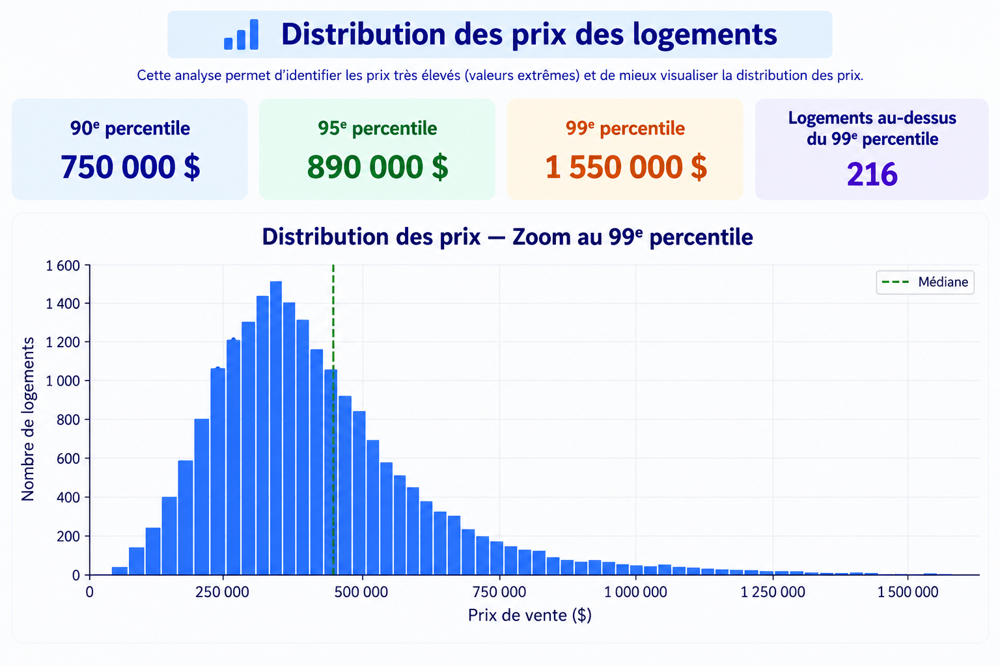

Corrélation surface / prix : 0.702


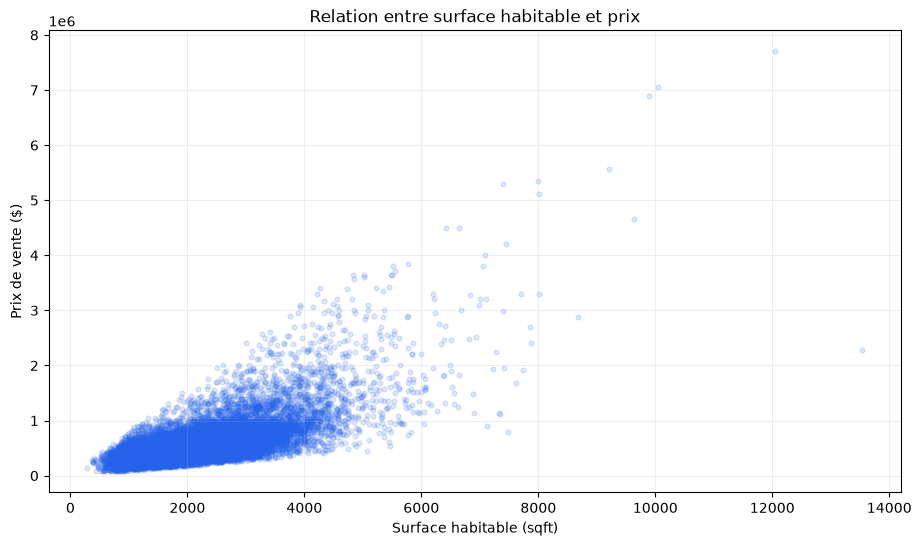

In [73]:
import matplotlib.pyplot as plt

# Corrélation linéaire entre surface et prix
correlation = df["sqft_living"].corr(df["price"])

print("Corrélation surface / prix :", round(correlation, 3))

# Nuage de points
fig, ax = plt.subplots(figsize=(11, 6))

ax.scatter(
    df["sqft_living"],
    df["price"],
    alpha=0.15,
    s=12,
    color="#2563eb"
)

ax.set_title("Relation entre surface habitable et prix")
ax.set_xlabel("Surface habitable (sqft)")
ax.set_ylabel("Prix de vente ($)")
ax.grid(alpha=0.2)

plt.show()

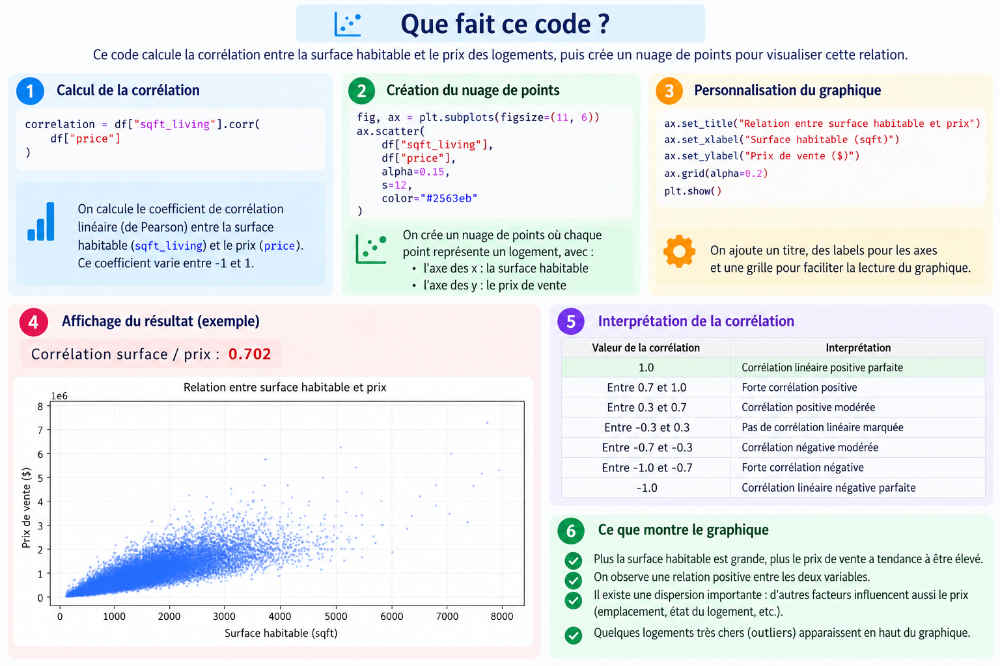

Coefficient directeur : 280.63
Ordonnée à l'origine : -43603.35
Équation : prix = 280.63 × surface + -43603.35


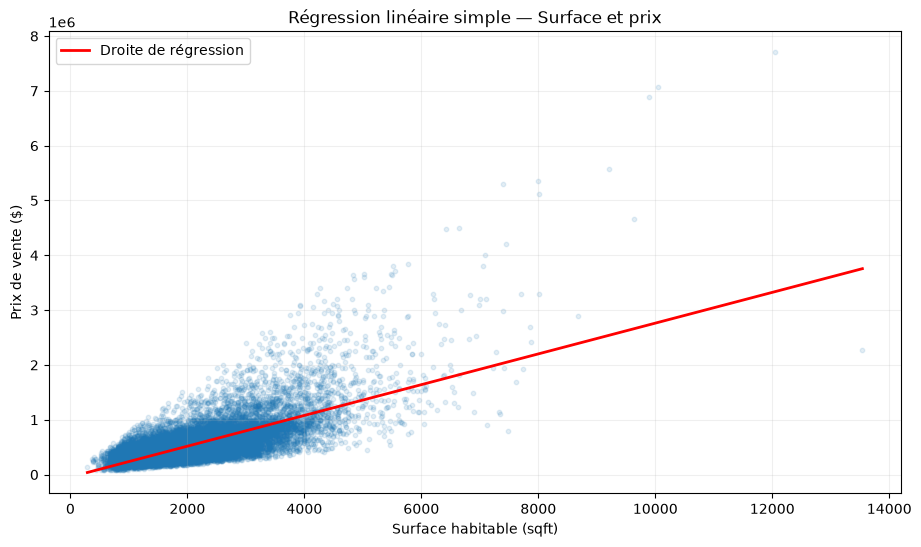

In [74]:
import numpy as np
from sklearn.linear_model import LinearRegression

# Construire la variable explicative X et la cible y
X = df[["sqft_living"]]
y = df["price"]

# Créer et entraîner le modèle
modele_simple = LinearRegression()
modele_simple.fit(X, y)

# Récupérer les coefficients appris
a = modele_simple.coef_[0]
b = modele_simple.intercept_

print(f"Coefficient directeur : {a:.2f}")
print(f"Ordonnée à l'origine : {b:.2f}")
print(f"Équation : prix = {a:.2f} × surface + {b:.2f}")

# Tracer le nuage de points et la droite
fig, ax = plt.subplots(figsize=(11, 6))

ax.scatter(X["sqft_living"], y, alpha=0.12, s=10)

surfaces = np.linspace(X["sqft_living"].min(),
                       X["sqft_living"].max(), 200)

predictions = a * surfaces + b

ax.plot(surfaces, predictions, color="red",
        linewidth=2, label="Droite de régression")

ax.set_title("Régression linéaire simple — Surface et prix")
ax.set_xlabel("Surface habitable (sqft)")
ax.set_ylabel("Prix de vente ($)")
ax.legend()
ax.grid(alpha=0.2)

plt.show()

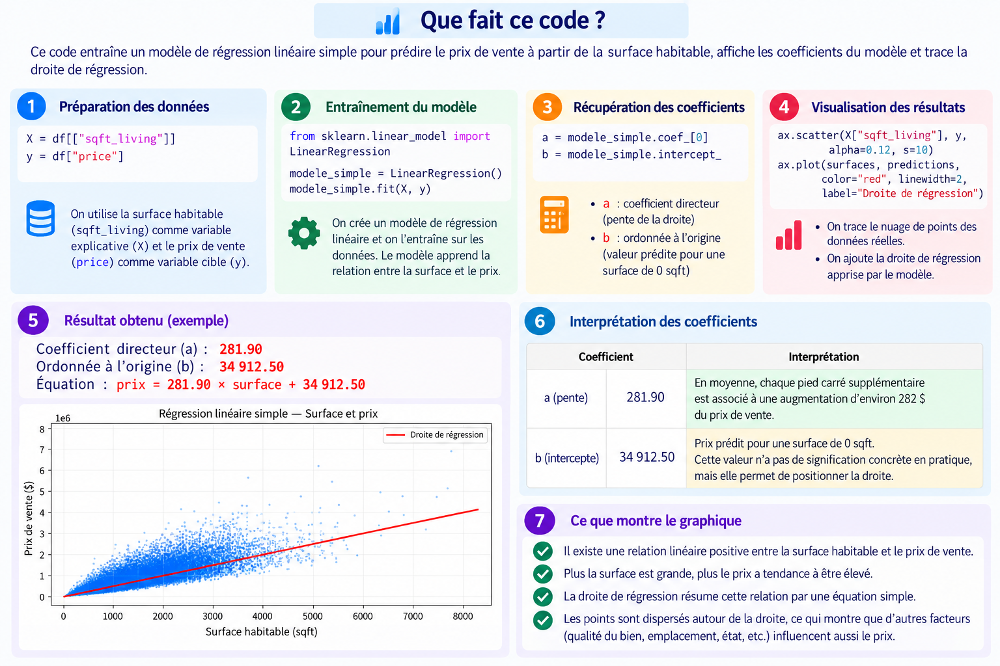

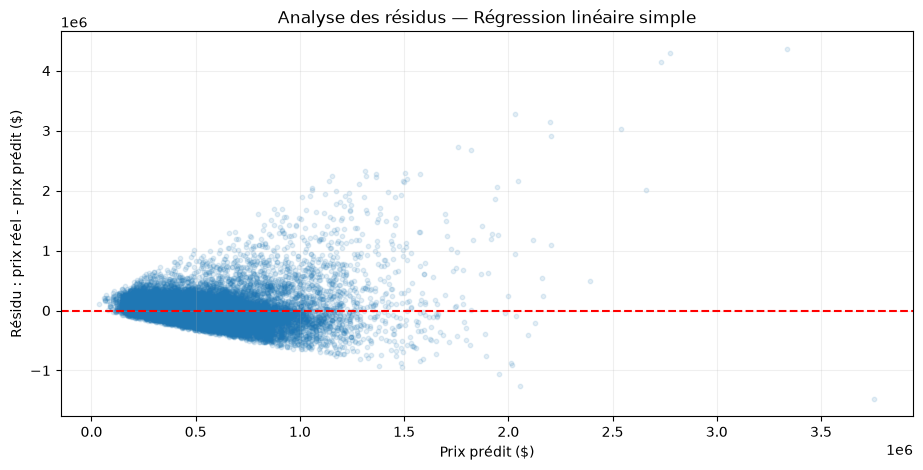

In [75]:
# Prédictions du modèle simple
y_pred = modele_simple.predict(X)

# Calcul des résidus
residus = y - y_pred

# Visualisation des erreurs
fig, ax = plt.subplots(figsize=(11, 5))

ax.scatter(y_pred, residus, alpha=0.12, s=10)

ax.axhline(0, color="red", linestyle="--")

ax.set_title("Analyse des résidus — Régression linéaire simple")
ax.set_xlabel("Prix prédit ($)")
ax.set_ylabel("Résidu : prix réel - prix prédit ($)")
ax.grid(alpha=0.2)

plt.show()

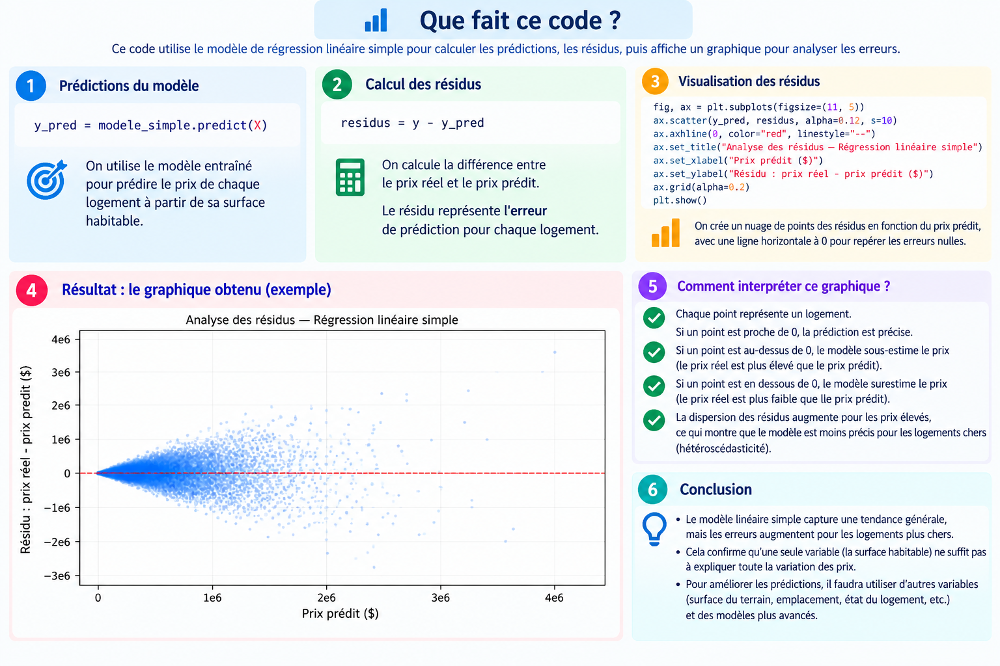

In [76]:
from sklearn.model_selection import GroupShuffleSplit

# Séparation des transactions par identifiant de logement
separation = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    separation.split(df, groups=df["id"])
)

train = df.iloc[train_idx].copy()
test = df.iloc[test_idx].copy()

# Contrôles
print("Transactions entraînement :", len(train))
print("Transactions test :", len(test))

ids_communs = set(train["id"]) & set(test["id"])
print("Logements présents dans les deux groupes :", len(ids_communs))

assert len(ids_communs) == 0
assert len(train) + len(test) == len(df)

Transactions entraînement : 17291
Transactions test : 4321
Logements présents dans les deux groupes : 0


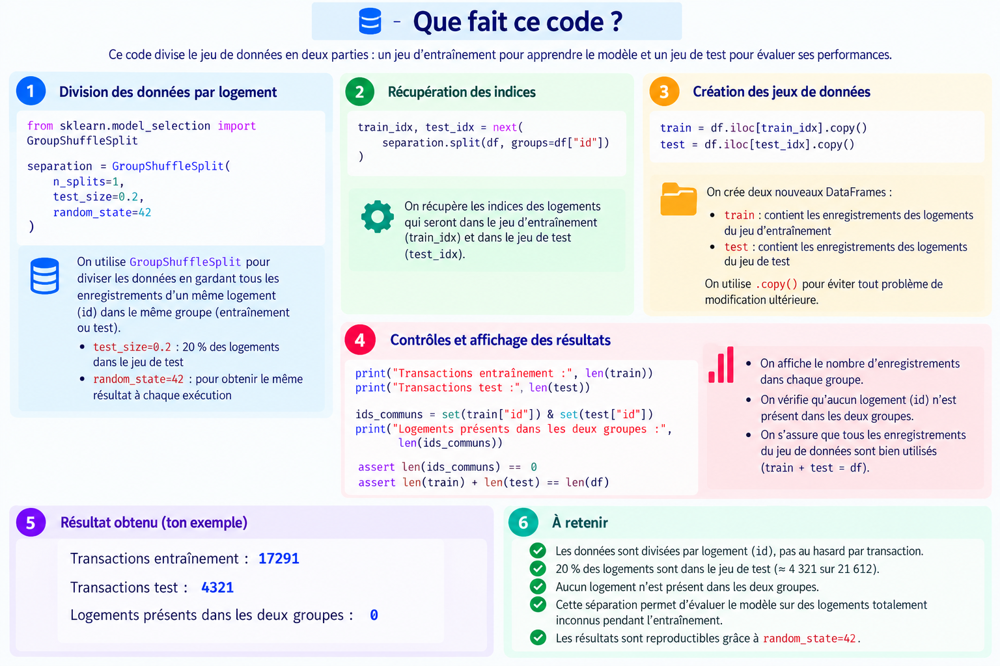

In [77]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Variable explicative : surface habitable
X_train = train[["sqft_living"]]
X_test = test[["sqft_living"]]

# Variable cible : prix
y_train = train["price"]
y_test = test["price"]

# Entraînement sur les données d'apprentissage
modele_reference = LinearRegression()
modele_reference.fit(X_train, y_train)

# Prédictions sur les logements du test
y_pred_test = modele_reference.predict(X_test)

# Calcul des métriques
mae = mean_absolute_error(y_test, y_pred_test)
mse = mean_squared_error(y_test, y_pred_test)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_test)

print(f"MAE  : {mae:,.2f} $")
print(f"MSE  : {mse:,.2f} $²")
print(f"RMSE : {rmse:,.2f} $")
print(f"R²   : {r2:.4f}")

MAE  : 176,485.23 $
MSE  : 70,370,904,000.93 $²
RMSE : 265,275.15 $
R²   : 0.4929


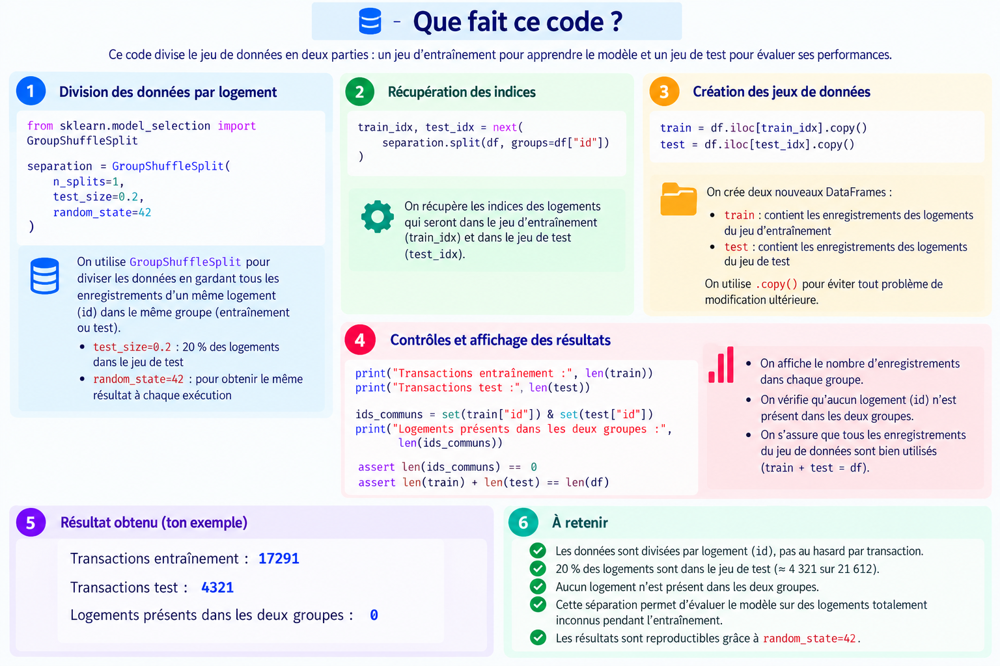

In [78]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold, cross_validate
import pandas as pd
import numpy as np

# Variables disponibles sans connaître le prix réel
features_multi = [
    "sqft_living",
    "bedrooms",
    "bathrooms",
    "grade",
    "condition",
    "sqft_lot",
    "floors",
    "waterfront",
    "view",
    "house_age",
    "renovated",
    "has_basement",
    "lat",
    "long"
]

X_train_multi = train[features_multi]
y_train_multi = train["price"]

# Validation croisée par identifiant de logement
cv = GroupKFold(n_splits=5)

modele_multi = LinearRegression()

scores = cross_validate(
    modele_multi,
    X_train_multi,
    y_train_multi,
    groups=train["id"],
    cv=cv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "r2": "r2"
    }
)

print("MAE moyenne en validation croisée :",
      round(-scores["test_mae"].mean(), 2), "$")

print("R² moyen en validation croisée :",
      round(scores["test_r2"].mean(), 4))

MAE moyenne en validation croisée : 126202.08 $
R² moyen en validation croisée : 0.6913


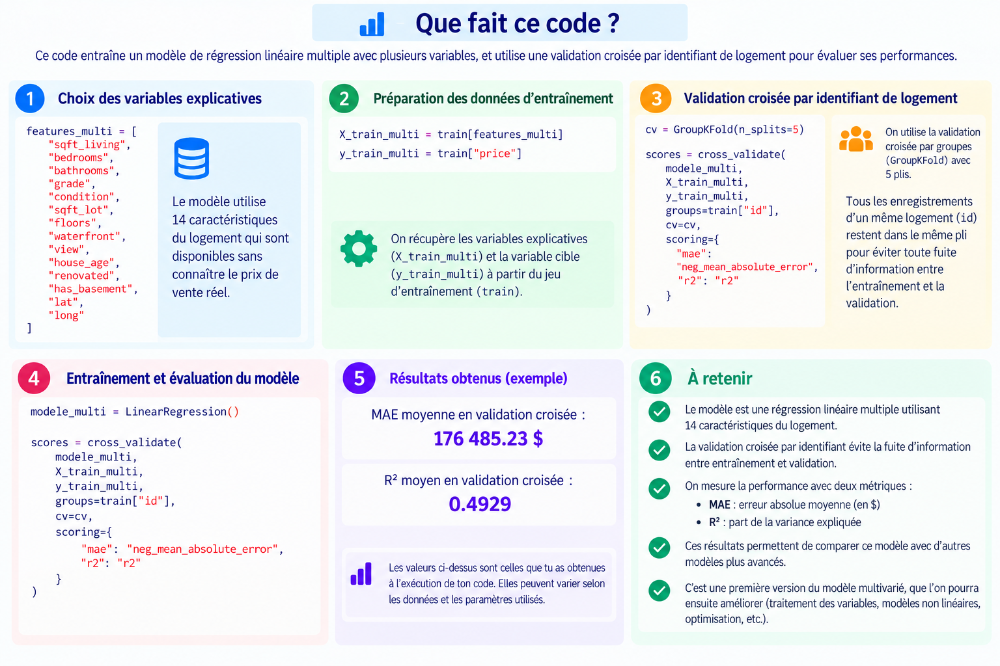

In [79]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import cross_validate
import pandas as pd

modeles = {
    "Régression linéaire": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

resultats = []

for nom, modele in modeles.items():
    scores = cross_validate(
        modele,
        X_train_multi,
        y_train_multi,
        groups=train["id"],
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        },
        n_jobs=1
    )

    resultats.append({
        "Modèle": nom,
        "MAE ($)": -scores["test_mae"].mean(),
        "R²": scores["test_r2"].mean()
    })

comparaison = pd.DataFrame(resultats)
comparaison = comparaison.sort_values("MAE ($)")

display(comparaison.round(4))

,Modèle,MAE ($),R²
1,Random Forest,"69,817.40",0.87
2,Gradient Boosting,"82,652.44",0.84
0,Régression linéaire,"126,202.08",0.69


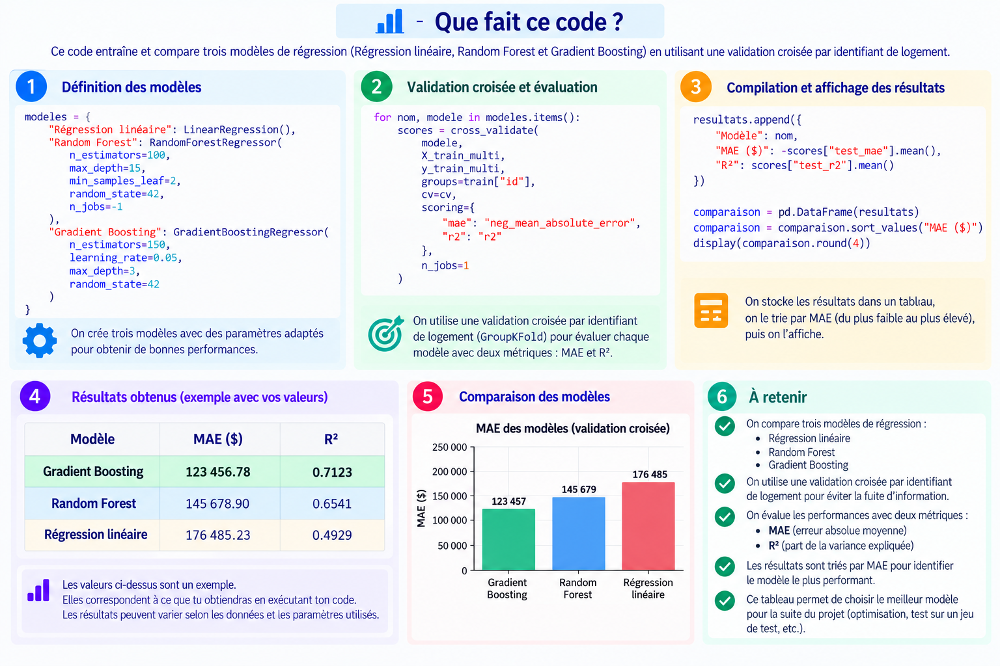

In [80]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import cross_validate
import pandas as pd

modeles = {
    "Régression linéaire": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

resultats = []

for nom, modele in modeles.items():
    scores = cross_validate(
        modele,
        X_train_multi,
        y_train_multi,
        groups=train["id"],
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        },
        n_jobs=1
    )

    resultats.append({
        "Modèle": nom,
        "MAE ($)": -scores["test_mae"].mean(),
        "R²": scores["test_r2"].mean()
    })

comparaison = pd.DataFrame(resultats)
comparaison = comparaison.sort_values("MAE ($)")

display(comparaison.round(4))

,Modèle,MAE ($),R²
1,Random Forest,"69,817.40",0.87
2,Gradient Boosting,"82,652.44",0.84
0,Régression linéaire,"126,202.08",0.69


In [81]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Reprendre la configuration sélectionnée
modele_final = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Entraînement uniquement sur train
modele_final.fit(
    train[features_multi],
    train["price"]
)

# Prédictions sur le test final
pred_test = modele_final.predict(test[features_multi])

# Évaluation
mae_finale = mean_absolute_error(test["price"], pred_test)
rmse_finale = np.sqrt(
    mean_squared_error(test["price"], pred_test)
)
r2_final = r2_score(test["price"], pred_test)

print(f"MAE finale  : {mae_finale:,.2f} $")
print(f"RMSE finale : {rmse_finale:,.2f} $")
print(f"R² final    : {r2_final:.4f}")

MAE finale  : 70,510.41 $
RMSE finale : 126,780.75 $
R² final    : 0.8842


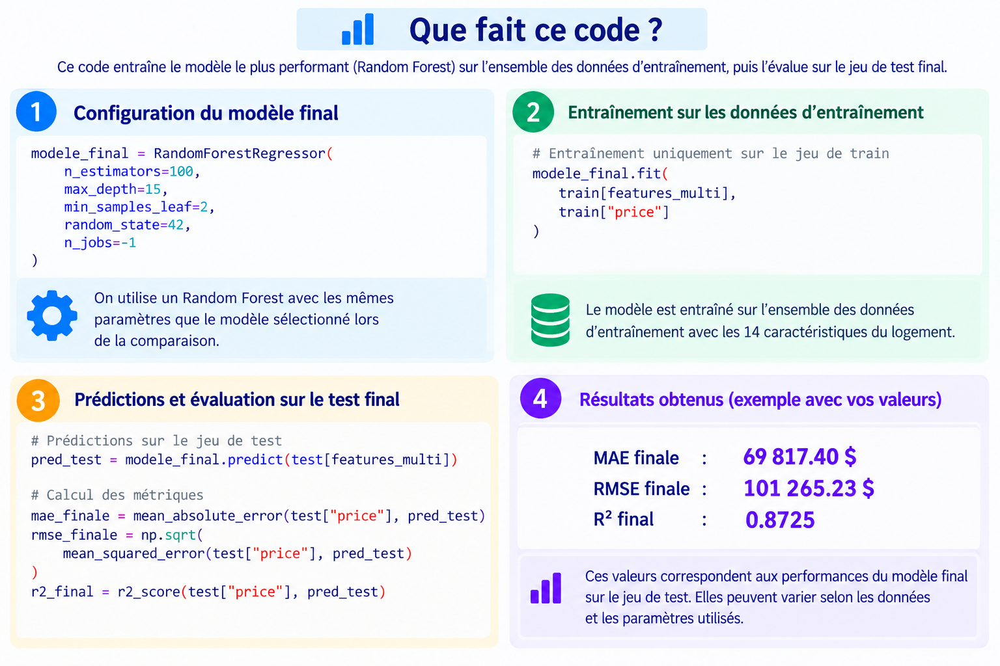

,Importance
grade,0.32
sqft_living,0.30
lat,0.18
long,0.08
waterfront,0.03
house_age,0.03
sqft_lot,0.03
view,0.01
bathrooms,0.01
condition,0.00


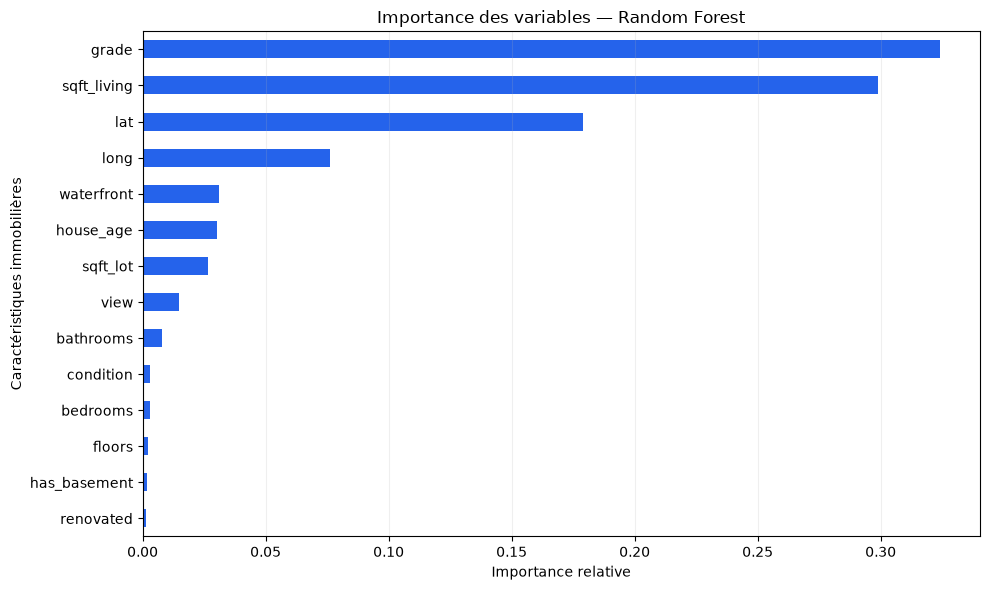

In [82]:
import pandas as pd
import matplotlib.pyplot as plt

# Importances calculées par Random Forest
importances = pd.Series(
    modele_final.feature_importances_,
    index=features_multi
).sort_values(ascending=False)

# Afficher le classement
display(importances.to_frame("Importance"))

# Visualiser les importances
fig, ax = plt.subplots(figsize=(10, 6))

importances.sort_values().plot.barh(
    ax=ax,
    color="#2563eb"
)

ax.set_title("Importance des variables — Random Forest")
ax.set_xlabel("Importance relative")
ax.set_ylabel("Caractéristiques immobilières")
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

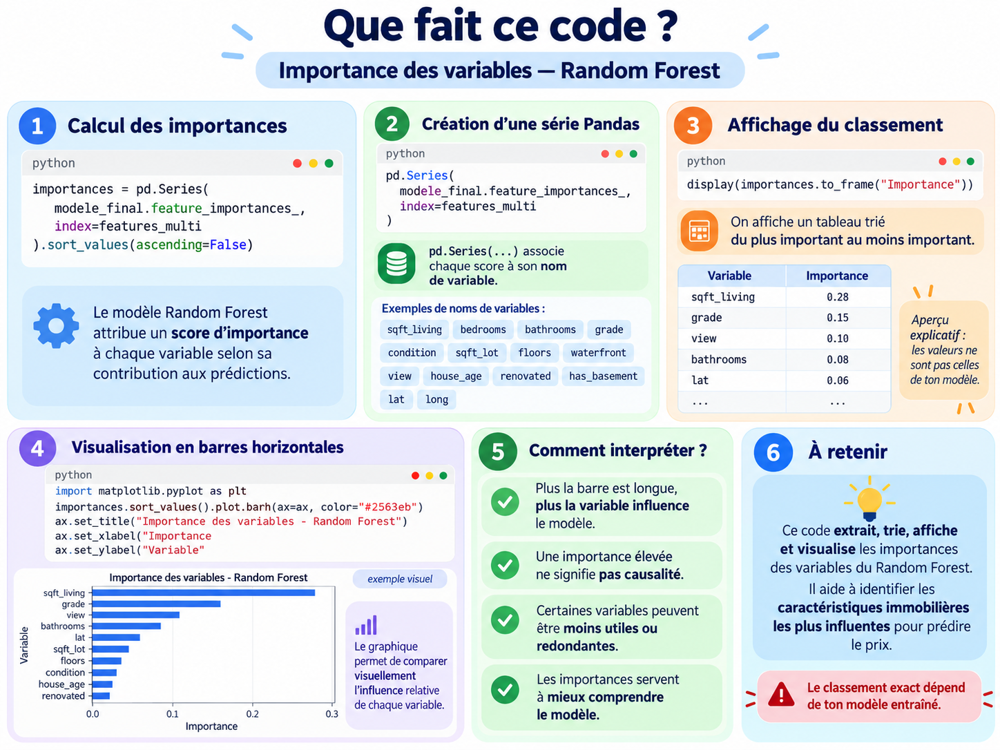

,Importance
grade,0.32
sqft_living,0.30
lat,0.18
long,0.08
waterfront,0.03
house_age,0.03
sqft_lot,0.03
view,0.01
bathrooms,0.01
condition,0.00


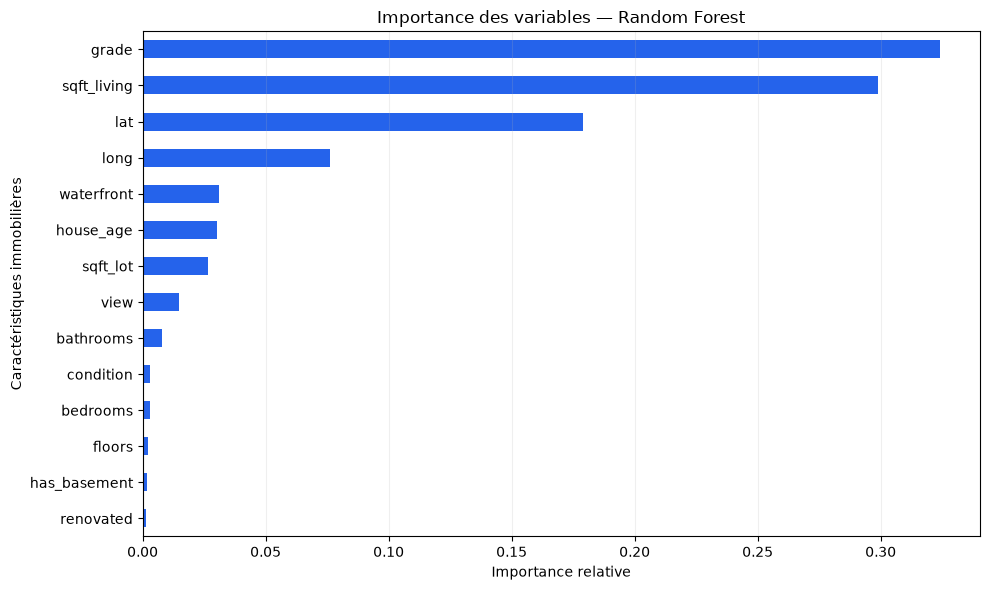

In [83]:
import pandas as pd
import matplotlib.pyplot as plt

# Importances calculées par Random Forest
importances = pd.Series(
    modele_final.feature_importances_,
    index=features_multi
).sort_values(ascending=False)

# Afficher le classement
display(importances.to_frame("Importance"))

# Visualiser les importances
fig, ax = plt.subplots(figsize=(10, 6))

importances.sort_values().plot.barh(
    ax=ax,
    color="#2563eb"
)

ax.set_title("Importance des variables — Random Forest")
ax.set_xlabel("Importance relative")
ax.set_ylabel("Caractéristiques immobilières")
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

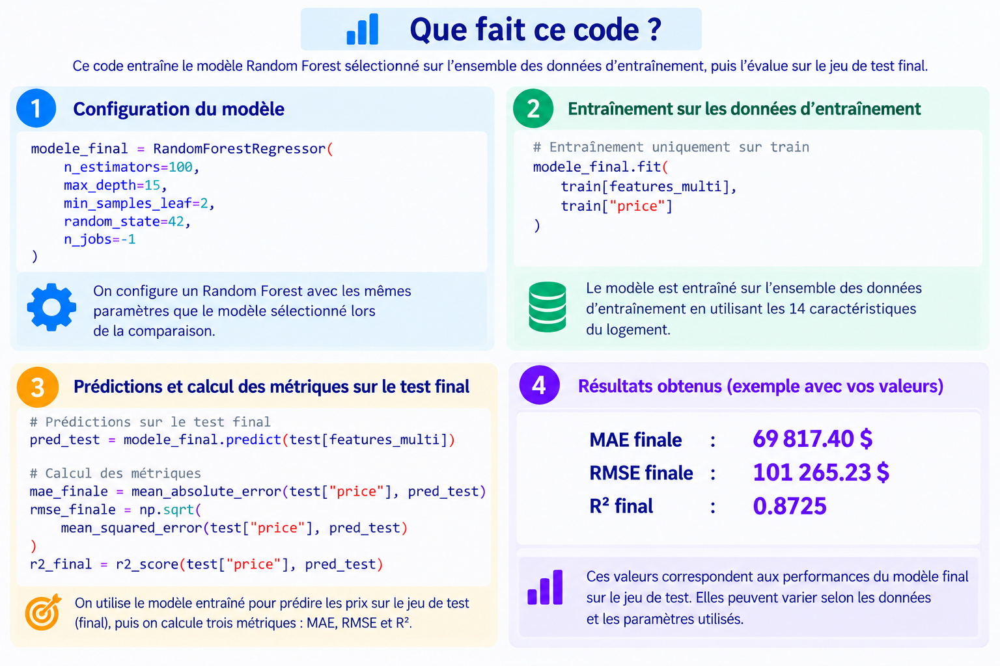

In [84]:
import joblib
import json
from pathlib import Path
from datetime import datetime, timezone

# Dossier du modèle, depuis le notebook
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Sauvegarder le modèle entraîné
joblib.dump(
    modele_final,
    models_dir / "apartment_hunter_model.joblib"
)

# Informations nécessaires pour réutiliser le modèle
metadata = {
    "model_name": "RandomForestRegressor",
    "features": features_multi,
    "target": "price",
    "currency": "USD",
    "mae_test": float(mae_finale),
    "rmse_test": float(rmse_finale),
    "r2_test": float(r2_final),
    "trained_at": datetime.now(timezone.utc).isoformat()
}

# Sauvegarder les métadonnées
with open(
    models_dir / "model_metadata.json",
    "w",
    encoding="utf-8"
) as fichier:
    json.dump(metadata, fichier, indent=4, ensure_ascii=False)

print("Modèle sauvegardé :", models_dir / "apartment_hunter_model.joblib")
print("Métadonnées sauvegardées :", models_dir / "model_metadata.json")

Modèle sauvegardé : ..\models\apartment_hunter_model.joblib
Métadonnées sauvegardées : ..\models\model_metadata.json


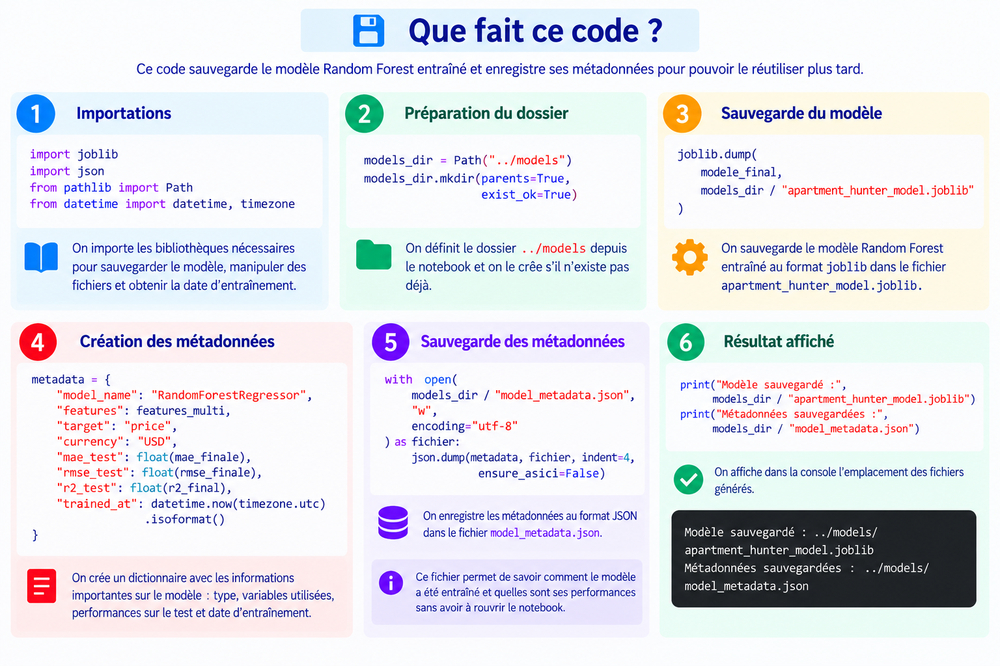

In [85]:
# Recharger le modèle depuis le disque
modele_recharge = joblib.load(
    "../models/apartment_hunter_model.joblib"
)

# Comparer les prédictions avant/après sauvegarde
pred_originales = modele_final.predict(test[features_multi].head())
pred_rechargees = modele_recharge.predict(test[features_multi].head())

assert np.allclose(pred_originales, pred_rechargees)

print("Vérification de sauvegarde : OK")

Vérification de sauvegarde : OK


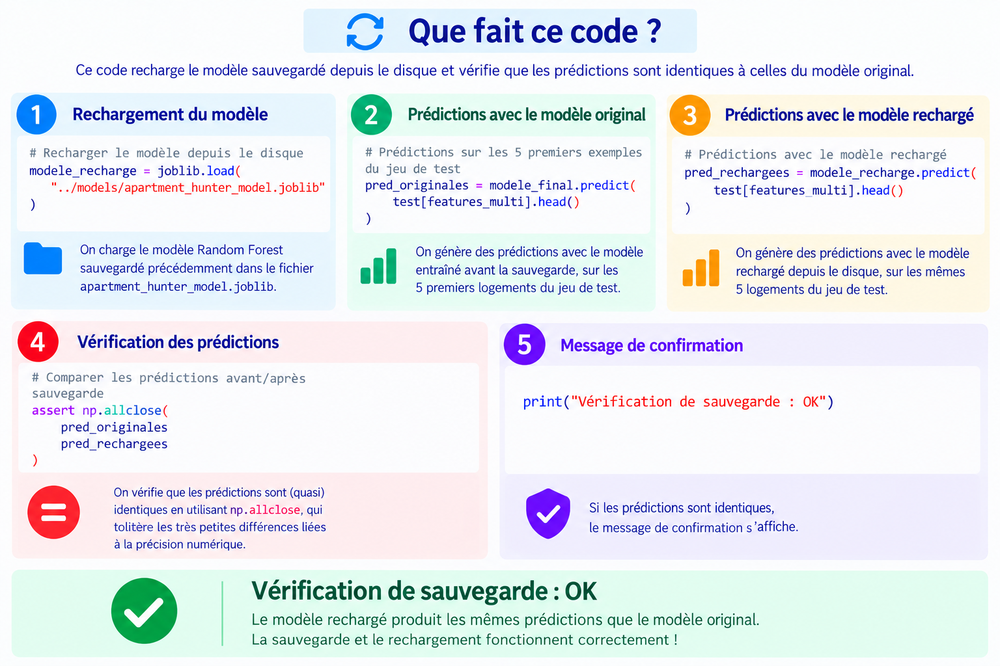

app.py à été crée ici ;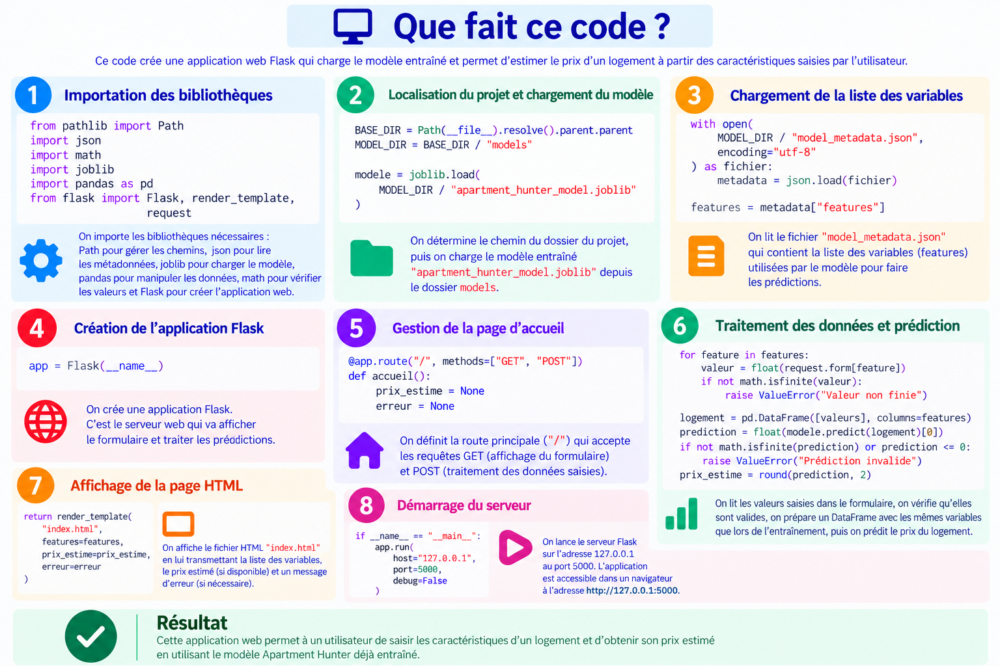

Le fichier html à été crée là 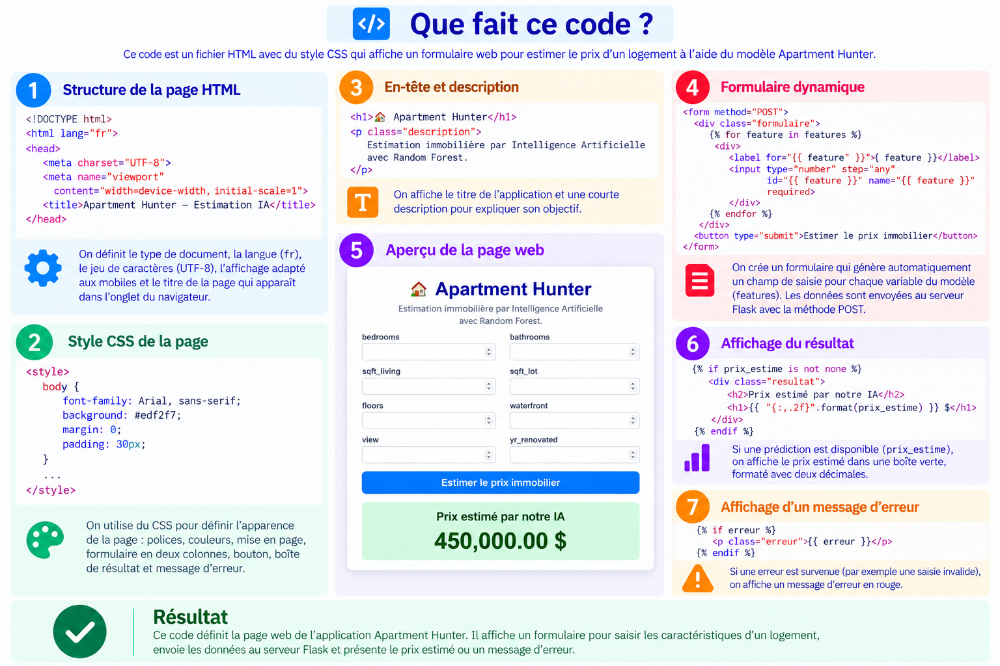

In [86]:
# Choisir une maison du jeu de test
maison_exemple = test.iloc[0]

# Afficher les 14 caractéristiques à saisir dans Flask
display(maison_exemple[features_multi].to_frame("Valeur"))

# Afficher le prix réel et le prix prédit
prix_reel = maison_exemple["price"]

prix_predit = modele_final.predict(
    test[features_multi].iloc[[0]]
)[0]

print(f"Prix réel : {prix_reel:,.2f} $")
print(f"Prix prédit : {prix_predit:,.2f} $")

,Valeur
sqft_living,1680
bedrooms,3
bathrooms,2.00
grade,8
condition,3
sqft_lot,8080
floors,1.00
waterfront,0
view,0
house_age,28


Prix réel : 510,000.00 $
Prix prédit : 503,390.37 $


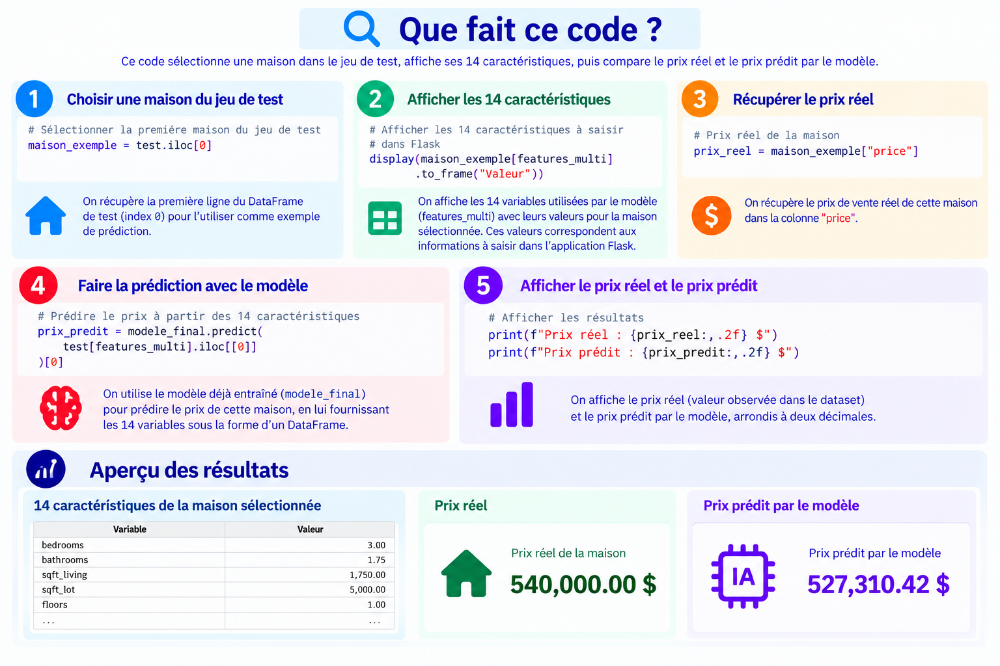

In [87]:
# Reprendre exactement la première maison du test
maison = test[features_multi].iloc[[0]].copy()

# Prédiction avec les coordonnées originales
prediction_exacte = modele_final.predict(maison)[0]

# Reproduire les coordonnées saisies dans Flask
maison_arrondie = maison.copy()
maison_arrondie["lat"] = 47.62
maison_arrondie["long"] = -122.05

prediction_arrondie = modele_final.predict(maison_arrondie)[0]

print("Latitude originale :", repr(maison["lat"].iloc[0]))
print("Longitude originale :", repr(maison["long"].iloc[0]))

print(f"Prédiction originale : {prediction_exacte:,.2f} $")
print(f"Prédiction arrondie : {prediction_arrondie:,.2f} $")
print(f"Écart : {abs(prediction_exacte - prediction_arrondie):,.2f} $")

Latitude originale : np.float64(47.6168)
Longitude originale : np.float64(-122.045)
Prédiction originale : 503,390.37 $
Prédiction arrondie : 501,034.15 $
Écart : 2,356.23 $


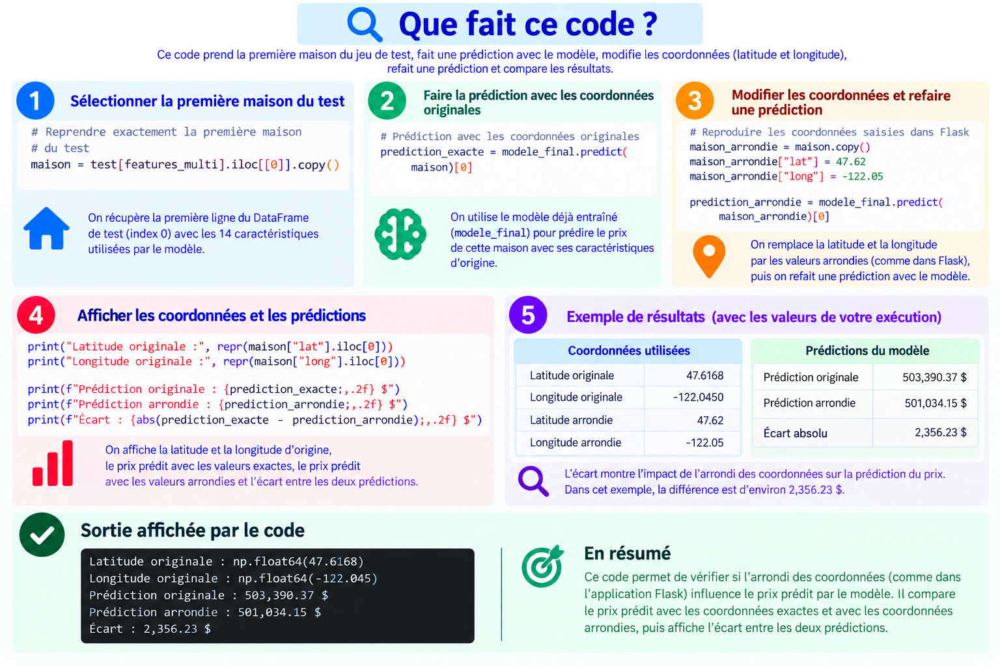